### Market Structure Multi-Scale Analysis V4

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import pywt
import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import fisher_exact
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)
from sklearn.feature_selection import (
    mutual_info_regression
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '1950-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

In [4]:
def get_fred_timeseries_data(
    observation_start: str,
    observation_end: str,
    series_mapping: dict[str, str] | None = None,
    frequency: str | None = None,
    aggregation_method: str | None = None,
) -> dict[str, pd.DataFrame]:
    observation_start = observation_start
    observation_end = observation_end
    base_fred_params = {
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": observation_start,
        "observation_end": observation_end,
        "frequency": frequency or "m",
        "aggregation_method": aggregation_method or "avg",
    }
    fred_dfs = {}
    for series_id, series_name in series_mapping.items():
        fred_params = base_fred_params.copy()
        fred_params["series_id"] = series_id
        fred_res = requests.get(fred_url, params=fred_params)
        fred_df = pd.DataFrame(fred_res.json()["observations"]).assign(**{
            "date": lambda df: pd.to_datetime(df["date"]),
            "value": lambda df: pd.to_numeric(df["value"], errors="coerce"),
            "interest_rate_type": series_name,
        })
        fred_dfs[series_name] = fred_df
        time.sleep(5)
        
    return fred_dfs

In [5]:
def delete_column(df):
    df = df.drop(columns=['realtime_start', 'realtime_end', 'interest_rate_type'])
    return df

#### S&P500(均等加重)時系列を取得

In [6]:
spxew_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^SPXEW",
    market=None,
    series_name="SPXEW"
))
spxew_df.tail()

取得件数: 4989


,value
date,
2026-10-23,8841.269531
2026-10-26,8772.370117
2026-10-27,8802.639648
2026-10-28,8809.419922
2026-10-29,8806.370117


#### S&P500(時価総額加重平均)時系列を取得

In [7]:
sp500_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
    series_name="GSPC"
))
sp500_df.tail()

取得件数: 19359


,value
date,
2026-10-23,7637.180176
2026-10-26,7639.700195
2026-10-27,7699.470215
2026-10-28,7735.560059
2026-10-29,7699.609863


#### Nasdaq100(均等加重)時系列を取得

In [8]:
ndxe_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^NDXE",
    market=None,
    series_name="NDXE"
))
ndxe_df.tail()

取得件数: 5150


,value
date,
2026-10-23,9893.769531
2026-10-26,9917.309570
2026-10-27,10010.910156
2026-10-28,10064.759766
2026-10-29,10038.530273


#### Nasdaq100(時価総額加重平均)時系列を取得

In [9]:
qqq_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
    series_name="IXIC"
))
qqq_df.tail()

取得件数: 14051


,value
date,
2026-10-23,25893.949219
2026-10-26,26026.869141
2026-10-27,26286.310547
2026-10-28,26541.609375
2026-10-29,26201.820312


#### iShares iBoxx $ High Yield Corporate Bond ETF

In [10]:
hyg_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="HYG",
    market=None,
    series_name="HYG"
))
hyg_df.tail()

取得件数: 4921


,value
date,
2026-10-23,76.889999
2026-10-26,77.080002
2026-10-27,77.300003
2026-10-28,77.709999
2026-10-29,77.480003


#### iShares 7-10 Year Treasury Bond ETF (IEF)

In [11]:
ief_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="IEF",
    market=None,
    series_name="IEF"
))
ief_df.tail()

取得件数: 6103


,value
date,
2026-10-23,91.230003
2026-10-26,91.160004
2026-10-27,91.059998
2026-10-28,91.059998
2026-10-29,91.110001


#### Federal Funds Effective Rate (DFF)

In [12]:
dff_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFF": "federal_funds_effective_rate"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["federal_funds_effective_rate"]
dff_df["date"] = pd.to_datetime(dff_df["date"])
dff_df = dff_df.set_index("date")
dff_df = delete_column(dff_df)
dff_df.head()

,value
date,
1954-07-01,1.13
1954-07-02,1.25
1954-07-03,1.25
1954-07-04,1.25
1954-07-05,0.88


#### Market Yield on U.S. Treasury Securities at 2-Year Constant Maturity, Quoted on an Investment Basis (DGS2)

In [13]:
dgs2_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS2": "two_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["two_year_treasury_yield"]
dgs2_df["date"] = pd.to_datetime(dgs2_df["date"])
dgs2_df = dgs2_df.set_index("date")
dgs2_df = delete_column(dgs2_df)
dgs2_df.head()

,value
date,
1976-06-01,7.26
1976-06-02,7.23
1976-06-03,7.22
1976-06-04,7.12
1976-06-07,7.09


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis (DGS10)

In [14]:
dgs10_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS10": "ten_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["ten_year_treasury_yield"]
dgs10_df["date"] = pd.to_datetime(dgs10_df["date"])
dgs10_df = dgs10_df.set_index("date")
dgs10_df = delete_column(dgs10_df)
dgs10_df.head()

,value
date,
1962-01-02,4.06
1962-01-03,4.03
1962-01-04,3.99
1962-01-05,4.02
1962-01-08,4.03


#### U.S. Dollars to Australian Dollar Spot Exchange Rate (DEXUSAL)

In [15]:
dxy_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DEXUSAL": "DXY"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["DXY"]
dxy_df["date"] = pd.to_datetime(dxy_df["date"])
dxy_df = dxy_df.set_index("date")
dxy_df = delete_column(dxy_df)
dxy_df.tail()

,value
date,
2026-10-19,0.6981
2026-10-20,0.7004
2026-10-21,0.7026
2026-10-22,0.7020
2026-10-23,0.7037


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis, Inflation-Indexed (DFII10)

In [16]:
real_yield_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFII10": "real_10y"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["real_10y"]
real_yield_df["date"] = pd.to_datetime(real_yield_df["date"])
real_yield_df = real_yield_df.set_index("date")
real_yield_df = delete_column(real_yield_df)
real_yield_df.tail()

,value
date,
2026-10-22,2.64
2026-10-23,2.66
2026-10-26,2.66
2026-10-27,2.64
2026-10-28,2.67


#### ICE BofA US High Yield Index Option-Adjusted Spread (BAMLH0A0HYM2)

In [17]:
credit_spread_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLH0A0HYM2": "credit_spread"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["credit_spread"]
credit_spread_df["date"] = pd.to_datetime(credit_spread_df["date"])
credit_spread_df = credit_spread_df.set_index("date")
credit_spread_df = delete_column(credit_spread_df)
credit_spread_df.tail()

,value
date,
2026-10-22,3.40
2026-10-23,3.38
2026-10-26,3.30
2026-10-27,3.18
2026-10-28,3.14


#### ICE BofA AAA US Corporate Index Option-Adjusted Spread (BAMLC0A1CAAA)

In [18]:
aaa_oas_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A1CAAA": "AAA_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["AAA_OAS"]
aaa_oas_df["date"] = pd.to_datetime(aaa_oas_df["date"])
aaa_oas_df = aaa_oas_df.set_index("date")
aaa_oas_df = delete_column(aaa_oas_df)
aaa_oas_df.tail()

,value
date,
2026-10-22,0.42
2026-10-23,0.44
2026-10-26,0.43
2026-10-27,0.42
2026-10-28,0.41


#### ICE BofA BBB US Corporate Index Option-Adjusted Spread (BAMLC0A4CBBB)

In [19]:
bbb_oas_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A4CBBB": "BBB_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["BBB_OAS"]
bbb_oas_df["date"] = pd.to_datetime(bbb_oas_df["date"])
bbb_oas_df = bbb_oas_df.set_index("date")
bbb_oas_df = delete_column(bbb_oas_df)
bbb_oas_df.tail()

,value
date,
2026-10-22,1.11
2026-10-23,1.13
2026-10-26,1.12
2026-10-27,1.09
2026-10-28,1.07


#### Federal Funds Effective Rate (FEDFUNDS)

In [20]:
ffer_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"FEDFUNDS": "ff_rate"},
    frequency='m',
    aggregation_method=aggregation_method
)["ff_rate"]
ffer_df["date"] = pd.to_datetime(ffer_df["date"])
ffer_df = ffer_df.set_index("date")
ffer_df = delete_column(ffer_df)
ffer_df.tail()

,value
date,
2026-05-01,3.63
2026-06-01,3.63
2026-07-01,3.63
2026-08-01,3.63
2026-09-01,3.75


#### データ統合

In [21]:
# ============================================================
# データ統合
# ============================================================
# 各データを共通フォーマットへ変換
df_list = [
    spxew_df.rename(columns={'value': "SPXEW"}),
    sp500_df.rename(columns={'value': "GSPC"}),
    ndxe_df.rename(columns={'value': "NDXE"}),
    qqq_df.rename(columns={'value': "IXIC"}),
    hyg_df.rename(columns={'value': "HYG"}),
    ief_df.rename(columns={'value': "IEF"}),
    dff_df.rename(columns={'value': "DFF"}),
    dgs2_df.rename(columns={'value': "DGS2"}),
    dgs10_df.rename(columns={'value': "DGS10"}),
    dxy_df.rename(columns={'value': "DXY"}),
    real_yield_df.rename(columns={'value': "DFII10"}),
    credit_spread_df.rename(columns={'value': "BAMLH0A0HYM2"}),
    aaa_oas_df.rename(columns={'value': "BAMLC0A1CAAA"}),
    bbb_oas_df.rename(columns={'value': "BAMLC0A4CBBB"}),
    ffer_df.rename(columns={'value': "FEDFUNDS"}),
]
# 日付で外部結合
market_df = pd.concat(df_list, axis=1, join="outer")
# 日付順にソート
market_df = market_df.sort_index()
# 重複日付除去
market_df = market_df[~market_df.index.duplicated(keep="first")]
# 欠損補完
market_df = market_df.ffill()
# 全列欠損行は削除
market_df = market_df.dropna(how="all")
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"V4_data_integration_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = market_df.copy()
df.to_csv(output_path)
# 確認
print("=" * 60)
print("Market Data Shape")
print(market_df.shape)
print("\nColumns")
print(market_df.columns.tolist())
print("\nHead")
display(market_df.head())
print("\nTail")
display(market_df.tail())

Market Data Shape
(27573, 15)

Columns
['SPXEW', 'GSPC', 'NDXE', 'IXIC', 'HYG', 'IEF', 'DFF', 'DGS2', 'DGS10', 'DXY', 'DFII10', 'BAMLH0A0HYM2', 'BAMLC0A1CAAA', 'BAMLC0A4CBBB', 'FEDFUNDS']

Head


/tmp/ipykernel_439/588195291.py:23: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  market_df = pd.concat(df_list, axis=1, join="outer")


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
1949-11-17,NaN,15.960000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-18,NaN,16.139999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-21,NaN,16.070000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-22,NaN,16.150000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-23,NaN,16.190001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Tail


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
2026-10-25,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,2.66,3.38,0.44,1.13,3.75
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.00,0.7037,2.66,3.30,0.43,1.12,3.75
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.70,4.99,0.7037,2.64,3.18,0.42,1.09,3.75
2026-10-28,8809.419922,7735.560059,10064.759766,26541.609375,77.709999,91.059998,3.88,4.67,5.05,0.7037,2.67,3.14,0.41,1.07,3.75
2026-10-29,8806.370117,7699.609863,10038.530273,26201.820312,77.480003,91.110001,3.88,4.67,5.05,0.7037,2.67,3.14,0.41,1.07,3.75


#### 1. Create Volatility Targets

Convert wavelet components into
volatility and stress indicators.


In [22]:
# 研究データの準備およびSWT分析
research_df = market_df.copy()
# 日付をdatetime型に変換
research_df.index = pd.to_datetime(research_df.index)
# GSPCの対数リターンを計算
research_df["GSPC_LOG_RET"] = (
    np.log(research_df["GSPC"])
    .diff()
)
# 欠損値を除去
research_df = research_df.dropna(subset=["GSPC_LOG_RET"])
# SWT
signal = research_df[
    "GSPC_LOG_RET"
].values
# 使用可能な信号長を計算
usable_length = (
    2 ** int(
        np.floor(
            np.log2(len(signal))
        )
    )
)
# 使用可能な信号長に合わせてデータを切り取る
research_df = (
    research_df
    .iloc[-usable_length:]
    .copy()
)
# SWT用の信号を再取得
signal = research_df["GSPC_LOG_RET"].values
# SWTの最大分解レベルを設定
MAX_LEVEL = 6
# SWTを実行して分解係数を取得
coeffs = pywt.swt(
    signal,
    wavelet="db4",
    level=MAX_LEVEL
)
# SWTの各レベルの詳細係数をデータフレームに追加
for level_idx, (_, detail) in enumerate(
    coeffs,
    start=1
):
    # 現在のレベルを計算
    level = (MAX_LEVEL - level_idx + 1)
    # データフレームに詳細係数を追加するための列名を作成
    research_df[f"GSPC_D{level}"] = detail
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"1_Create_Volatility_Targets_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
research_df.to_csv(output_path)
print("saved:", output_path)
# データフレームの末尾を表示
research_df.tail()


saved: /workspace/data/1_Create_Volatility_Targets_2026-10-30.csv


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,...,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS,GSPC_LOG_RET,GSPC_D6,GSPC_D5,GSPC_D4,GSPC_D3,GSPC_D2,GSPC_D1
date,,,,,,,,,,,,,,,,,,,,,
2026-10-25,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,...,0.44,1.13,3.75,0.000000,0.004725,-0.011296,0.000937,-0.008350,-0.002346,-0.000206
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.00,0.7037,...,0.43,1.12,3.75,0.000330,0.004692,-0.011328,0.002928,-0.006708,-0.000028,-0.007998
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.70,4.99,0.7037,...,0.42,1.09,3.75,0.007793,0.004728,-0.011917,0.005141,-0.003389,-0.004581,0.010596
2026-10-28,8809.419922,7735.560059,10064.759766,26541.609375,77.709999,91.059998,3.88,4.67,5.05,0.7037,...,0.41,1.07,3.75,0.004676,0.004707,-0.012254,0.005883,-0.000042,-0.004326,-0.006213
2026-10-29,8806.370117,7699.609863,10038.530273,26201.820312,77.480003,91.110001,3.88,4.67,5.05,0.7037,...,0.41,1.07,3.75,-0.004658,0.004600,-0.011668,0.004891,0.000646,0.001162,0.000581


#### 2. Create Stress Measures

Volatility proxy Stress proxy

In [23]:
# 各レベルの詳細係数の絶対値および二乗を計算してデータフレームに追加
for level in range(1, 7):
    # 現在のレベルの詳細係数の絶対値および二乗を計算
    research_df[f"GSPC_D{level}_ABS"] = (
        research_df[f"GSPC_D{level}"]
        .abs()
    )
    # 現在のレベルの詳細係数の二乗を計算
    research_df[f"GSPC_D{level}_SQ"] = (research_df[f"GSPC_D{level}"] ** 2)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"2_Create_Stress_Measures_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
research_df.to_csv(output_path)
print("saved:", output_path)
# データフレームの末尾を表示
research_df.tail()

saved: /workspace/data/2_Create_Stress_Measures_2026-10-30.csv


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,...,GSPC_D2_ABS,GSPC_D2_SQ,GSPC_D3_ABS,GSPC_D3_SQ,GSPC_D4_ABS,GSPC_D4_SQ,GSPC_D5_ABS,GSPC_D5_SQ,GSPC_D6_ABS,GSPC_D6_SQ
date,,,,,,,,,,,,,,,,,,,,,
2026-10-25,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,...,0.002346,5.504853e-06,0.008350,6.973072e-05,0.000937,8.784434e-07,0.011296,0.000128,0.004725,0.000022
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.00,0.7037,...,0.000028,7.755370e-10,0.006708,4.499258e-05,0.002928,8.573266e-06,0.011328,0.000128,0.004692,0.000022
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.70,4.99,0.7037,...,0.004581,2.098626e-05,0.003389,1.148677e-05,0.005141,2.643469e-05,0.011917,0.000142,0.004728,0.000022
2026-10-28,8809.419922,7735.560059,10064.759766,26541.609375,77.709999,91.059998,3.88,4.67,5.05,0.7037,...,0.004326,1.871517e-05,0.000042,1.784739e-09,0.005883,3.461185e-05,0.012254,0.000150,0.004707,0.000022
2026-10-29,8806.370117,7699.609863,10038.530273,26201.820312,77.480003,91.110001,3.88,4.67,5.05,0.7037,...,0.001162,1.349787e-06,0.000646,4.173705e-07,0.004891,2.392649e-05,0.011668,0.000136,0.004600,0.000021


#### 3. Create Stationary Features

In [24]:
# クレジットスプレッドおよびログリターンの計算
research_df["HY_OAS_CHANGE"] = (
    research_df["BAMLH0A0HYM2"]
    .diff()
)
# BBBクレジットスプレッドの変化を計算
research_df["BBB_OAS_CHANGE"] = (
    research_df["BAMLC0A4CBBB"]
    .diff()
)
# HYGのログリターンを計算
research_df["HYG_LOG_RET"] = (
    np.log(
        research_df["HYG"]
    )
    .diff()
)
# IEFのログリターンを計算
research_df["IEF_LOG_RET"] = (
    np.log(
        research_df["IEF"]
    )
    .diff()
)
# 欠損値を削除
research_df = research_df.dropna()
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"3_Create_Stationary_Features_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
research_df.to_csv(output_path)
print("saved:", output_path)
# データフレームの末尾を表示
research_df.tail()

saved: /workspace/data/3_Create_Stationary_Features_2026-10-30.csv


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,...,GSPC_D4_ABS,GSPC_D4_SQ,GSPC_D5_ABS,GSPC_D5_SQ,GSPC_D6_ABS,GSPC_D6_SQ,HY_OAS_CHANGE,BBB_OAS_CHANGE,HYG_LOG_RET,IEF_LOG_RET
date,,,,,,,,,,,,,,,,,,,,,
2026-10-25,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,...,0.000937,8.784434e-07,0.011296,0.000128,0.004725,0.000022,0.00,0.00,0.000000,0.000000
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.00,0.7037,...,0.002928,8.573266e-06,0.011328,0.000128,0.004692,0.000022,-0.08,-0.01,0.002468,-0.000768
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.70,4.99,0.7037,...,0.005141,2.643469e-05,0.011917,0.000142,0.004728,0.000022,-0.12,-0.03,0.002850,-0.001098
2026-10-28,8809.419922,7735.560059,10064.759766,26541.609375,77.709999,91.059998,3.88,4.67,5.05,0.7037,...,0.005883,3.461185e-05,0.012254,0.000150,0.004707,0.000022,-0.04,-0.02,0.005290,0.000000
2026-10-29,8806.370117,7699.609863,10038.530273,26201.820312,77.480003,91.110001,3.88,4.67,5.05,0.7037,...,0.004891,2.392649e-05,0.011668,0.000136,0.004600,0.000021,0.00,0.00,-0.002964,0.000549


#### 4. Mutual Information

Credit signal vs Volatility target

In [25]:
# 特徴量とマルチスケールGSPCターゲットとの間の相互情報量を算出する
features = [
    "HY_OAS_CHANGE",
    "BBB_OAS_CHANGE",
    "HYG_LOG_RET",
    "IEF_LOG_RET",
]
results = []
# 各特徴量と各マルチスケールGSPCターゲットの相互情報量を計算するループ
for feature in features:
    # 各マルチスケールGSPCターゲットに対して相互情報量を計算する
    for level in range(1, 7):
        # 対象のマルチスケールGSPCターゲットを設定する
        target = (f"GSPC_D{level}_SQ")
        # 対象の特徴量とターゲットのデータを抽出し、欠損値を除去する
        tmp = (
            research_df[[feature, target]]
            .dropna()
        )
        # 特徴量とターゲットを設定する
        X = tmp[[feature]]
        y = tmp[target]
        # 相互情報量を計算する
        mi = mutual_info_regression(X, y, random_state=42)[0]
        # 計算結果を保存する
        results.append(
            {
                "feature": feature,
                "target": target,
                "mi": mi,
            }
        )
# 計算結果をデータフレームに変換する
mi_vol_df = pd.DataFrame(results)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"4_Mutual_Information_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
mi_vol_df.to_csv(output_path)
print("saved:", output_path)
# 相互情報量の上位30件を表示する
mi_vol_df.sort_values("mi",ascending=False).head(30)

saved: /workspace/data/4_Mutual_Information_2026-10-30.csv


,feature,target,mi
13,HYG_LOG_RET,GSPC_D2_SQ,0.036133
7,BBB_OAS_CHANGE,GSPC_D2_SQ,0.030638
2,HY_OAS_CHANGE,GSPC_D3_SQ,0.021870
6,BBB_OAS_CHANGE,GSPC_D1_SQ,0.021829
10,BBB_OAS_CHANGE,GSPC_D5_SQ,0.019018
19,IEF_LOG_RET,GSPC_D2_SQ,0.018609
11,BBB_OAS_CHANGE,GSPC_D6_SQ,0.018069
18,IEF_LOG_RET,GSPC_D1_SQ,0.013539
3,HY_OAS_CHANGE,GSPC_D4_SQ,0.011848
9,BBB_OAS_CHANGE,GSPC_D4_SQ,0.004756


#### 5. Volatility Mutual Information Heatmap

saved: /workspace/data/figures/5_Volatility_Mutual_Information_Heatmap_1950-01-01_2026-10-30.png


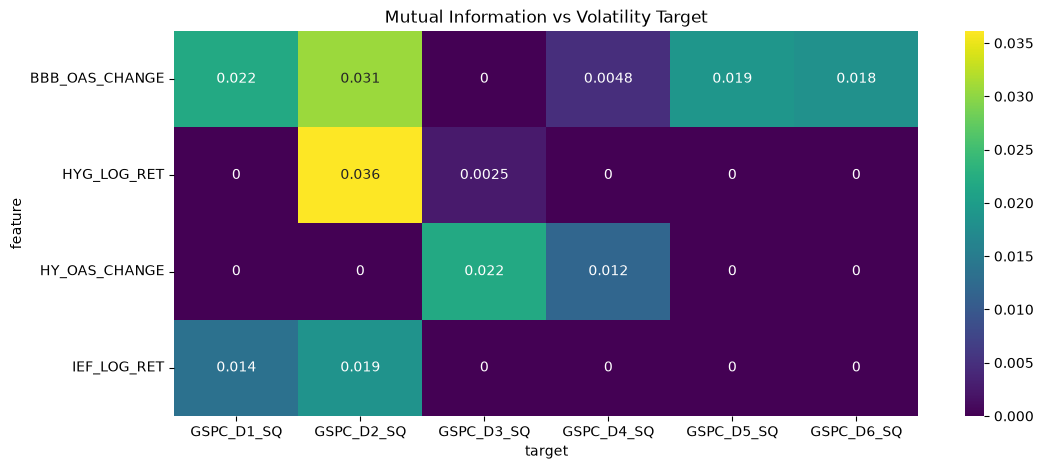

In [26]:
# 相互情報量のヒートマップを作成する
heatmap_df = (
    mi_vol_df
    .pivot(
        index="feature",
        columns="target",
        values="mi"
    )
)
plt.figure(figsize=(12, 5))
sns.heatmap(
    heatmap_df,
    annot=True,
    cmap="viridis"
)
plt.title("Mutual Information vs Volatility Target")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"5_Volatility_Mutual_Information_Heatmap_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# グラフを表示
plt.show()

#### 6. Event Study

HY spread widening vs market stress

In [27]:
# 特徴量のイベント別統計量を算出する
FEATURE = "HY_OAS_CHANGE"
TARGET = "GSPC_D4_SQ"
# 対象の特徴量とターゲットを設定する
tmp = (
    research_df[[FEATURE, TARGET]]
    .dropna()
    .copy()
)
# イベント列を初期化する
tmp["event"] = "NORMAL"
# 上位10%をWIDENING、下位10%をTIGHTENINGとしてイベントを分類する
tmp.loc[
    tmp[FEATURE] >= tmp[FEATURE].quantile(0.9),
    "event"
] = "WIDENING"
# 下位10%をTIGHTENINGとしてイベントを分類する
tmp.loc[
    tmp[FEATURE]
    <= tmp[FEATURE].quantile(0.1),
    "event"
] = "TIGHTENING"
# イベントごとの統計量を算出する
event_summary = (
    tmp
    .groupby("event")[TARGET]
    .agg(
        mean="mean",
        median="median",
        std="std",
        count="count"
    )
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"6_Event_Study_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
event_summary.to_csv(output_path)
print("saved:", output_path)
# イベントごとの統計量を表示する
event_summary

saved: /workspace/data/6_Event_Study_2026-10-30.csv


,mean,median,std,count
event,,,,
NORMAL,0.000048,0.000020,0.000118,858
TIGHTENING,0.000055,0.000022,0.000110,124
WIDENING,0.000057,0.000020,0.000119,113


#### 7. Tail Risk Classification

Define volatility stress regime.

In [28]:
# ボラティリティストレスの判定を行う
TARGET = "GSPC_D4_SQ"
# ボラティリティストレスの閾値を設定する
threshold = (
    research_df[TARGET]
    .quantile(0.95)
)
# ボラティリティストレスの判定を行う
research_df["VOL_STRESS"] = (
    research_df[TARGET]
    >= threshold
).astype(int)
# ボラティリティストレスの集計を行う
research_df[
    "VOL_STRESS"
].value_counts()

VOL_STRESS
0    1040
1      55
Name: count, dtype: int64

#### 8. Stress Probability

Does credit spread widening
increase stress probability?

In [29]:

# 特徴量を設定する
FEATURE = "HY_OAS_CHANGE"
tmp = (
    research_df[
        [FEATURE, "VOL_STRESS"]
    ]
    .dropna()
    .copy()
)
# 特徴量を10分位に分割する
tmp["bucket"] = pd.qcut(
    tmp[FEATURE],
    q=10,
    labels=False,
    duplicates="drop"
)
# 各バケットごとのボラティリティストレス率を算出する
stress_rate = (
    tmp
    .groupby("bucket")
    ["VOL_STRESS"]
    .mean()
    .reset_index()
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"8_Stress_Probability_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
stress_rate.to_csv(output_path)
print("saved:", output_path)
# 各バケットごとのボラティリティストレス率を表示する
stress_rate

saved: /workspace/data/8_Stress_Probability_2026-10-30.csv


,bucket,VOL_STRESS
0,0,0.080645
1,1,0.043103
2,2,0.079208
3,3,0.032787
4,4,0.009091
5,5,0.060870
6,6,0.098039


#### 9. Stress Probability Visualization

saved: /workspace/data/figures/9_Stress_Probability_Visualization_1950-01-01_2026-10-30.png


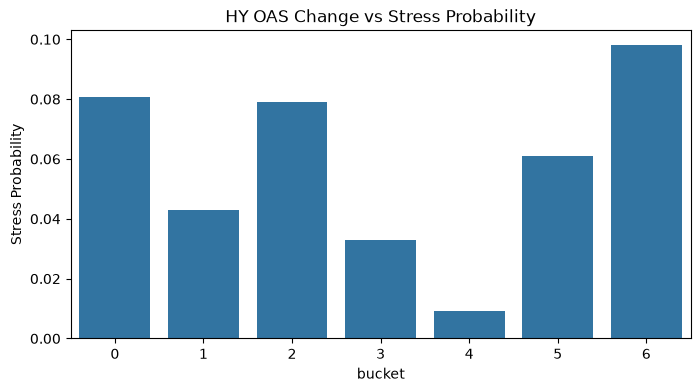

In [30]:
# 各バケットごとのボラティリティストレス率を可視化する
plt.figure(figsize=(8, 4))
sns.barplot(
    data=stress_rate,
    x="bucket",
    y="VOL_STRESS"
)
plt.ylabel("Stress Probability")
plt.title("HY OAS Change vs Stress Probability")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"9_Stress_Probability_Visualization_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# グラフを表示
plt.show()

# Market Structure Multi-Scale Analysis V4

## 検証目的

V1〜V3では、信用スプレッド変化率とS&P500 Wavelet成分との間に弱い依存関係が確認された。しかし、将来リターンの予測力は限定的であった。

そのためV4では研究テーマを

```text
リターン予測
↓
ボラティリティ・テールリスク予測
```

へ変更し、

```text
信用市場の悪化
↓
市場ストレス発生
```

という仮説を検証した。

---

## 検証手順

1. S&P500対数リターンをSWTでWavelet分解し D1〜D6 を生成
2. 各Wavelet成分の二乗をボラティリティ代理変数として作成

```text
GSPC_D1_SQ
～
GSPC_D6_SQ
```

3. 説明変数として以下を使用

```text
HY_OAS_CHANGE
BBB_OAS_CHANGE
HYG_LOG_RET
IEF_LOG_RET
```

4. Mutual Information により非線形依存関係を評価
5. Event Study により信用スプレッド急変時の市場ストレスを比較
6. 上位5%のボラティリティを

```text
VOL_STRESS
```

として定義し、ストレス発生確率を分析した。 【1-789d56】【2-2ff5e3】

---

## 検証結果

Mutual Information の上位は以下であった。

```text
HYG_LOG_RET    → GSPC_D2_SQ   0.036
BBB_OAS_CHANGE → GSPC_D2_SQ   0.031
HY_OAS_CHANGE  → GSPC_D3_SQ   0.022
```

信用市場変数とボラティリティとの弱い非線形依存関係は確認されたが、強い説明力は認められなかった。 【1-789d56】

Event Studyでは、

```text
NORMAL     4.84e-05
TIGHTENING 5.47e-05
WIDENING   5.66e-05
```

となり、信用スプレッド急変時の平均ボラティリティ上昇は限定的であった。 【3-b80f45】

一方で Stress Probability 分析では、

```text
最低バケット   8.1%
最高バケット   9.8%
```

となり、信用スプレッド急拡大局面で市場ストレス発生率が上昇する傾向が確認された。 【2-2ff5e3】

---

## 結論

現時点では、

```text
信用市場
↓
将来リターン予測
```

および

```text
信用市場
↓
平均ボラティリティ予測
```

を支持する十分な証拠は得られていない。

一方で、

```text
信用スプレッド急変
↓
極端な市場ストレス発生確率上昇
```

を示唆する兆候が観測された。

今後は、

```text
Surrogate Test
Bootstrap
多変量ストレスモデル
閾値推定
```

を実施し、検出された関係が偶然ではないことを検証する必要がある。